# 01 - Image Preprocessing for Receipt OCR

**Goal:** Prepare receipt images for better OCR accuracy

**Key Techniques:**
1. Grayscale conversion - Reduces complexity
2. Adaptive thresholding - Handles uneven lighting
3. Upscaling (1.5-2×) - Improves character recognition
4. Deskewing - Straightens rotated receipts

> **Why this matters:** OCR accuracy improves more from preprocessing than from model changes.

## Setup

In [1]:
import cv2
import numpy as np
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# For displaying images in notebook
%matplotlib inline

# Path to images folder
IMAGES_DIR = Path("../images")
print(f"Images directory: {IMAGES_DIR.absolute()}")

Images directory: /Users/jeffersonqiu/Desktop/projects/bcg_learning/llm_ocr/notebooks/../images


## Step 1: Load a Sample Receipt Image

First, let's load a receipt image. Make sure you have at least one image in the `images/` folder.

In [3]:
# List available images
image_files = list(IMAGES_DIR.glob("*.[jJpP][pPnN][gG]*")) + list(IMAGES_DIR.glob("*.webp"))
print(f"Found {len(image_files)} images:")
for f in image_files:
    print(f"  - {f.name}")

if not image_files:
    print("\n⚠️  No images found! Please add a receipt image to the images/ folder.")

Found 1 images:
  - receipt-ocr-original.jpg


Loading: receipt-ocr-original.jpg


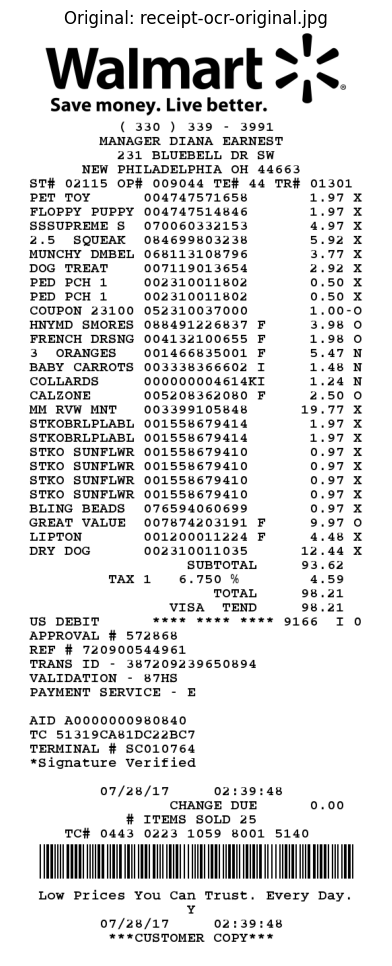

Image shape: (1373, 554, 3)


In [4]:
# Load the first image (or specify your own)
if image_files:
    image_path = image_files[0]
    print(f"Loading: {image_path.name}")
    
    # Load with OpenCV (BGR format)
    original = cv2.imread(str(image_path))
    
    # Convert to RGB for display
    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(8, 12))
    plt.imshow(original_rgb)
    plt.title(f"Original: {image_path.name}")
    plt.axis('off')
    plt.show()
    
    print(f"Image shape: {original.shape}")
else:
    print("❌ No image to load")

## Step 2: Convert to Grayscale

**Why grayscale?**
- Reduces 3 channels (RGB) to 1 channel
- Simplifies processing
- Text is typically black on white - color doesn't help

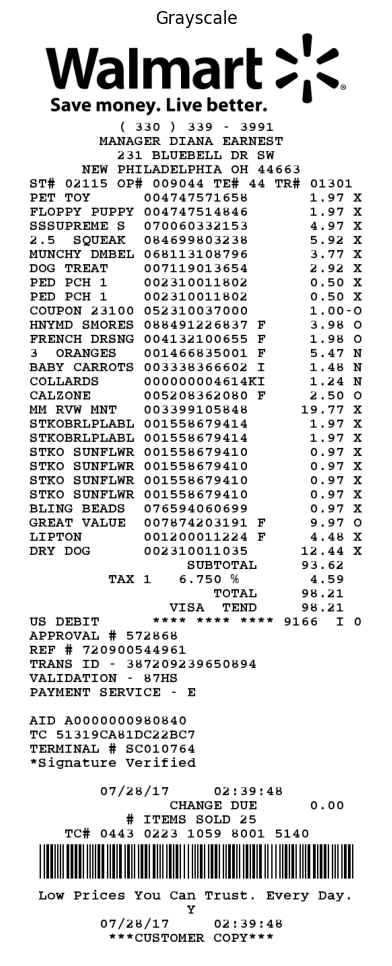

Grayscale shape: (1373, 554)


In [5]:
# Convert to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 12))
plt.imshow(gray, cmap='gray')
plt.title("Grayscale")
plt.axis('off')
plt.show()

print(f"Grayscale shape: {gray.shape}")

## Step 3: Adaptive Thresholding

**Why adaptive (not global) thresholding?**
- Receipts often have uneven lighting
- Adaptive threshold calculates different thresholds for different regions
- Results in cleaner black/white separation

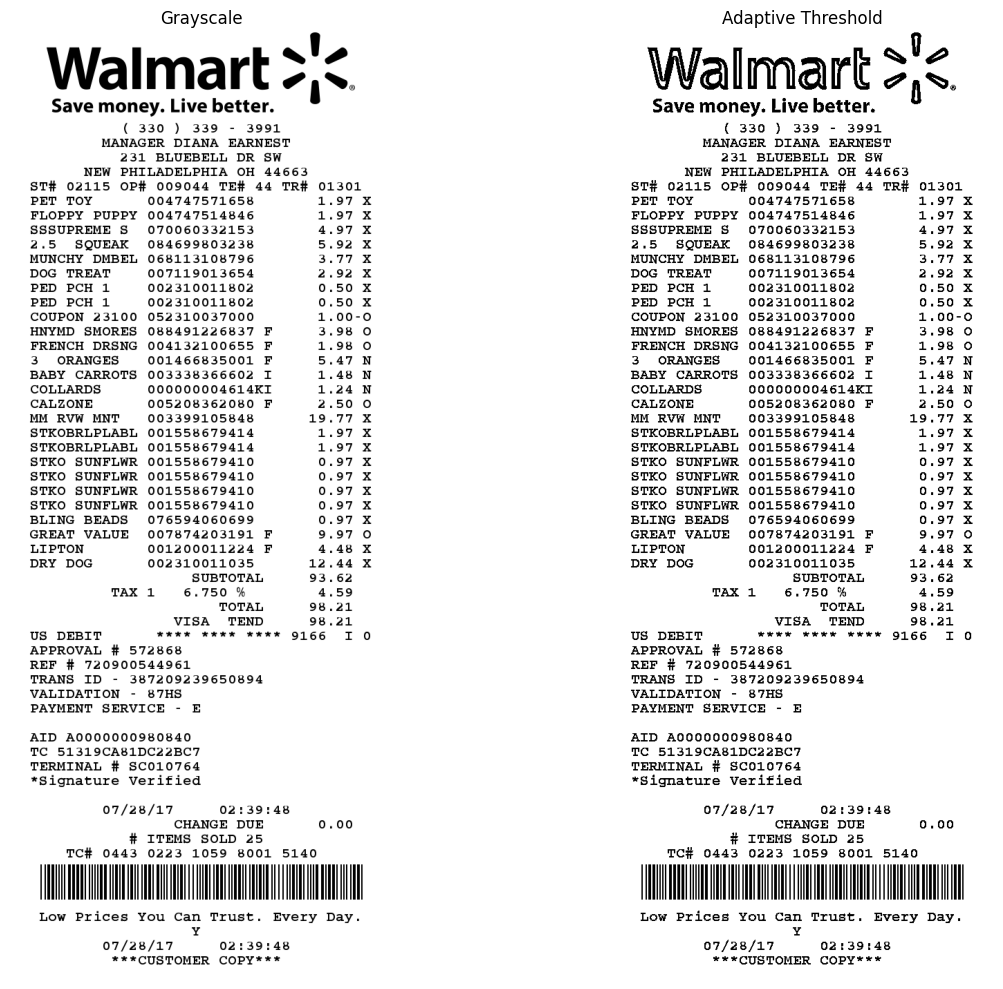

In [6]:
# Apply adaptive thresholding
# Parameters:
#   - maxValue: 255 (white)
#   - adaptiveMethod: ADAPTIVE_THRESH_GAUSSIAN_C (weighted mean of neighborhood)
#   - thresholdType: THRESH_BINARY (above threshold = white)
#   - blockSize: 11 (neighborhood size, must be odd)
#   - C: 2 (constant subtracted from mean)

thresh = cv2.adaptiveThreshold(
    gray, 
    255, 
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    cv2.THRESH_BINARY, 
    11, 
    2
)

# Compare original gray vs thresholded
fig, axes = plt.subplots(1, 2, figsize=(14, 10))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title("Grayscale")
axes[0].axis('off')

axes[1].imshow(thresh, cmap='gray')
axes[1].set_title("Adaptive Threshold")
axes[1].axis('off')

plt.tight_layout()
plt.show()

## Step 4: Upscaling (Optional)

**Why upscale?**
- OCR models work better with larger text
- 1.5-2× scaling often improves accuracy
- But increases processing time

In [7]:
# Upscale by 1.5x
scale_factor = 1.5
width = int(thresh.shape[1] * scale_factor)
height = int(thresh.shape[0] * scale_factor)

upscaled = cv2.resize(thresh, (width, height), interpolation=cv2.INTER_CUBIC)

print(f"Original size: {thresh.shape}")
print(f"Upscaled size: {upscaled.shape}")

Original size: (1373, 554)
Upscaled size: (2059, 831)


## Step 5: Deskewing (Optional)

**Why deskew?**
- Receipts are often photographed at an angle
- OCR works best on horizontal text
- We detect the dominant angle and rotate to correct

In [8]:
def deskew(image):
    """
    Detect skew angle and rotate image to correct it.
    
    Uses Hough Line Transform to find dominant lines,
    then calculates the median angle.
    """
    # Invert for edge detection (text becomes white)
    inverted = cv2.bitwise_not(image)
    
    # Detect edges
    edges = cv2.Canny(inverted, 50, 150, apertureSize=3)
    
    # Detect lines using Hough Transform
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, 100, minLineLength=100, maxLineGap=10)
    
    if lines is None:
        print("No lines detected, skipping deskew")
        return image, 0
    
    # Calculate angles of detected lines
    angles = []
    for line in lines:
        x1, y1, x2, y2 = line[0]
        angle = np.degrees(np.arctan2(y2 - y1, x2 - x1))
        # Only consider near-horizontal lines
        if abs(angle) < 45:
            angles.append(angle)
    
    if not angles:
        print("No horizontal lines detected, skipping deskew")
        return image, 0
    
    # Use median angle to reduce outlier impact
    median_angle = np.median(angles)
    print(f"Detected skew angle: {median_angle:.2f}°")
    
    # Rotate image to correct skew
    (h, w) = image.shape[:2]
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, median_angle, 1.0)
    rotated = cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_CUBIC, 
                              borderMode=cv2.BORDER_REPLICATE)
    
    return rotated, median_angle

# Apply deskewing
deskewed, angle = deskew(upscaled)
print(f"Applied rotation: {angle:.2f}°")

Detected skew angle: 0.00°
Applied rotation: 0.00°


## Final Comparison: Before vs After

Let's see the full preprocessing pipeline result.

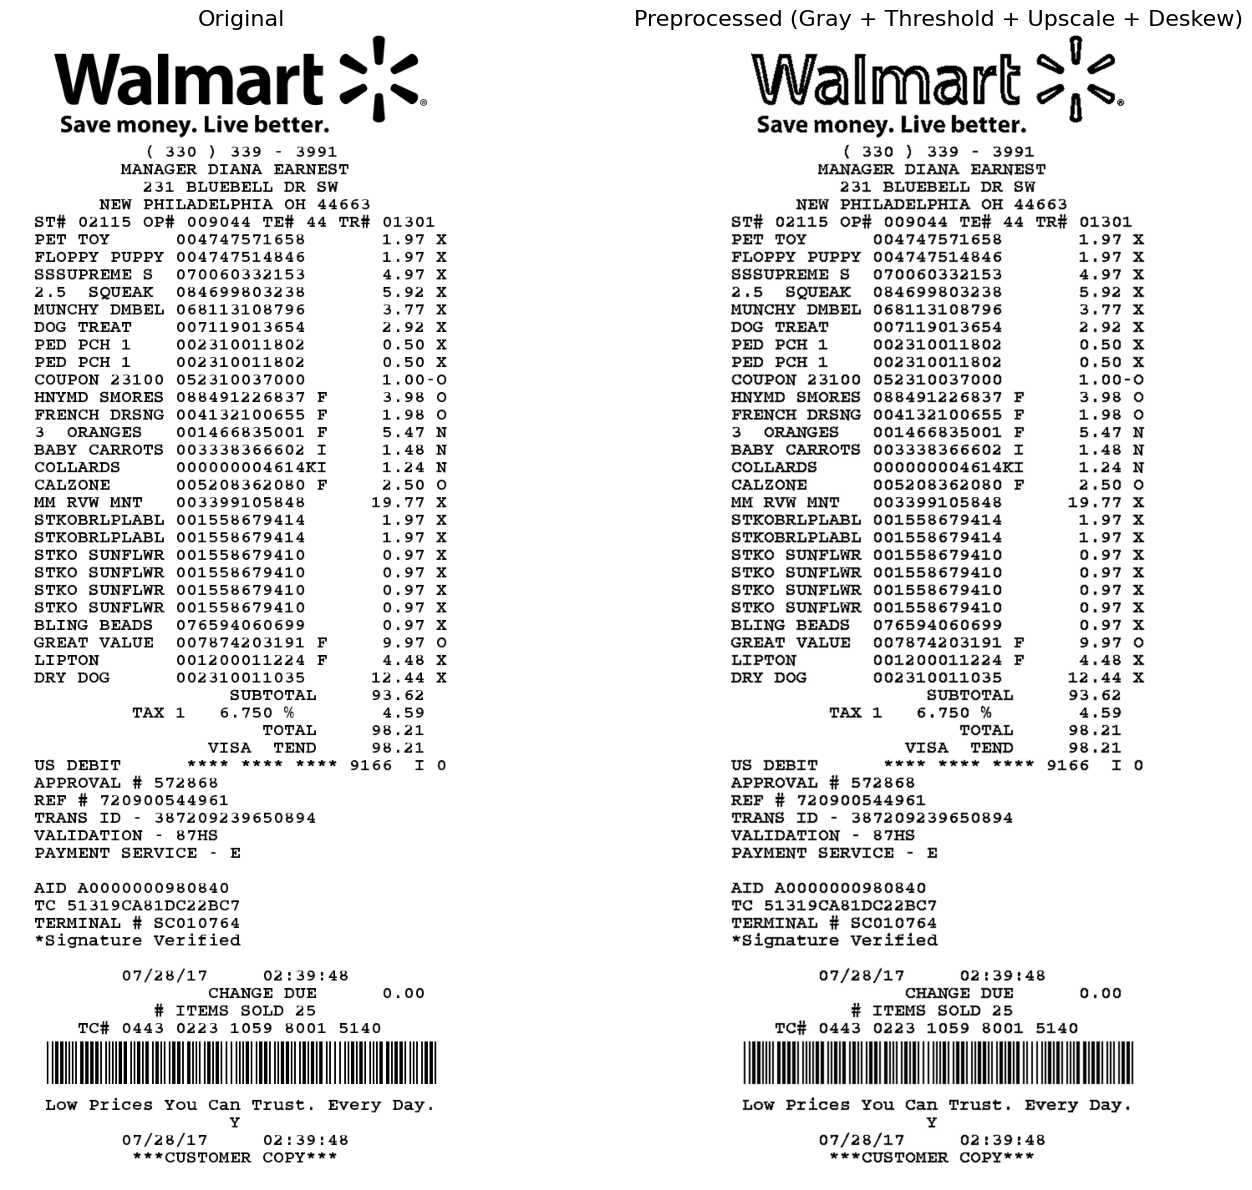

In [9]:
# Side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 12))

axes[0].imshow(original_rgb)
axes[0].set_title("Original", fontsize=16)
axes[0].axis('off')

axes[1].imshow(deskewed, cmap='gray')
axes[1].set_title("Preprocessed (Gray + Threshold + Upscale + Deskew)", fontsize=16)
axes[1].axis('off')

plt.tight_layout()
plt.show()

## Save Preprocessed Image

Save the preprocessed image so we can use it in the next notebook.

In [10]:
# Save preprocessed image
output_path = Path("../out") / f"preprocessed_{image_path.stem}.png"
cv2.imwrite(str(output_path), deskewed)
print(f"✅ Saved preprocessed image to: {output_path}")

✅ Saved preprocessed image to: ../out/preprocessed_receipt-ocr-original.png


## Complete Preprocessing Function

Here's the complete function we'll convert to a module later.

In [11]:
def preprocess_receipt(image_path: str, scale_factor: float = 1.5) -> np.ndarray:
    """
    Complete preprocessing pipeline for receipt images.
    
    Args:
        image_path: Path to the receipt image
        scale_factor: How much to upscale (default 1.5x)
    
    Returns:
        Preprocessed image as numpy array
    """
    # Load image
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not load image: {image_path}")
    
    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Adaptive thresholding
    thresh = cv2.adaptiveThreshold(
        gray, 255, 
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
        cv2.THRESH_BINARY, 
        11, 2
    )
    
    # Upscale
    width = int(thresh.shape[1] * scale_factor)
    height = int(thresh.shape[0] * scale_factor)
    upscaled = cv2.resize(thresh, (width, height), interpolation=cv2.INTER_CUBIC)
    
    # Deskew
    deskewed, _ = deskew(upscaled)
    
    return deskewed

# Test the complete function
if image_files:
    result = preprocess_receipt(image_files[0])
    print(f"✅ Preprocessing complete! Output shape: {result.shape}")

Detected skew angle: 0.00°
✅ Preprocessing complete! Output shape: (2059, 831)


---

## 🎯 Key Takeaways

1. **Preprocessing is critical** - Often more impactful than model choice
2. **Adaptive thresholding** handles uneven receipt lighting
3. **Upscaling** helps OCR detect small text
4. **Deskewing** corrects angled photos

## ➡️ Next: `02_ocr.ipynb`

In the next notebook, we'll run PaddleOCR on the preprocessed images.